In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('/content/shopping_behavior_updated.csv')

In [3]:
df.head() #Display the first 5 rows

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [4]:
df.shape #Dataset shape.

(3900, 18)

In [5]:
df.dtypes # Data types of each column

,0
Customer ID,int64
Age,int64
Gender,object
Item Purchased,object
Category,object
Purchase Amount (USD),int64
Location,object
Size,object
Color,object
Season,object


In [6]:
df.describe() #Statistical summary.

,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.000000,3900.000000,3900.000000,3900.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.749949,25.351538
std,1125.977353,15.207589,23.685392,0.716223,14.447125
min,1.000000,18.000000,20.000000,2.500000,1.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000
50%,1950.500000,44.000000,60.000000,3.700000,25.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000


In [7]:
df.isnull().sum() #Missing values.

,0
Customer ID,0
Age,0
Gender,0
Item Purchased,0
Category,0
Purchase Amount (USD),0
Location,0
Size,0
Color,0
Season,0


In [8]:
df.duplicated().sum() #Duplicate records.

np.int64(0)

"After checking, the dataset contains no missing values or duplicate records, so no rows were dropped."

In [9]:
df.info() #Incorrect data types.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   object 
 3   Item Purchased          3900 non-null   object 
 4   Category                3900 non-null   object 
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   object 
 7   Size                    3900 non-null   object 
 8   Color                   3900 non-null   object 
 9   Season                  3900 non-null   object 
 10  Review Rating           3900 non-null   float64
 11  Subscription Status     3900 non-null   object 
 12  Shipping Type           3900 non-null   object 
 13  Discount Applied        3900 non-null   object 
 14  Promo Code Used         3900 non-null   

In [10]:
df['Gender'].unique()

array(['Male', 'Female'], dtype=object)

In [11]:
df['Category'].unique()

array(['Clothing', 'Footwear', 'Outerwear', 'Accessories'], dtype=object)

In [12]:
df['Size'].unique()

array(['L', 'S', 'M', 'XL'], dtype=object)

In [13]:
df['Subscription Status'].unique()

array(['Yes', 'No'], dtype=object)

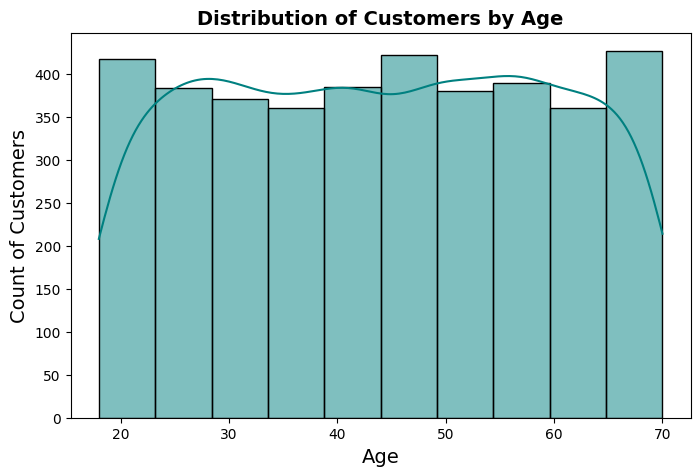

In [14]:
plt.figure(figsize= [8,5])
sns.histplot(df['Age'], kde= True, color= 'teal', bins= 10)
plt.title('Distribution of Customers by Age', fontsize = 14, fontweight = 'bold')
plt.xlabel('Age', fontsize = 14)
plt.ylabel('Count of Customers', fontsize = 14)
plt.show()

Equal Market Representation: No specific age group dominates the store's sales; young adults, middle-aged customers, and seniors are all equally active buyers, with each age segment maintaining a steady volume of around 350 to 425 customers.

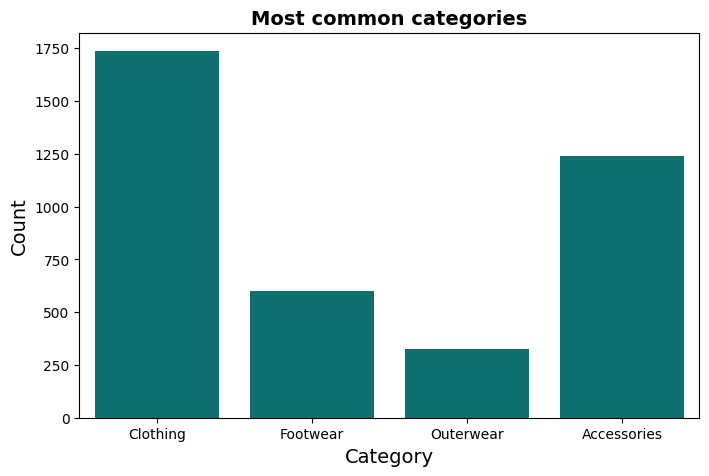

In [15]:
plt.figure(figsize= [8,5])
sns.countplot(data= df, x= 'Category', color= 'teal')
plt.title('Most common categories', fontsize= 14, fontweight= 'bold')
plt.xlabel('Category', fontsize= 14)
plt.ylabel('Count', fontsize= 14)
plt.show()

Top Categories: "Clothing" is the most popular product category by a significant margin, accounting for nearly 45% of total customer purchases (over 1,700 items sold).

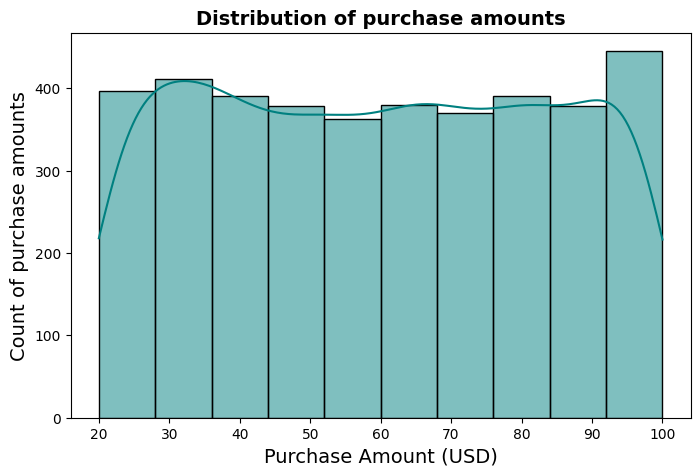

In [16]:
plt.figure(figsize= [8,5])
sns.histplot(df['Purchase Amount (USD)'], kde= True, color= 'teal', bins= 10)
plt.title('Distribution of purchase amounts', fontsize= 14, fontweight= 'bold')
plt.xlabel('Purchase Amount (USD)', fontsize= 14)
plt.ylabel('Count of purchase amounts', fontsize= 14)
plt.show()

Uniform Distribution with Premium Peak: The purchase amounts generally follow a uniform distribution, but with a noticeable and significant surge (peak) in high-ticket purchases between 92 and 100

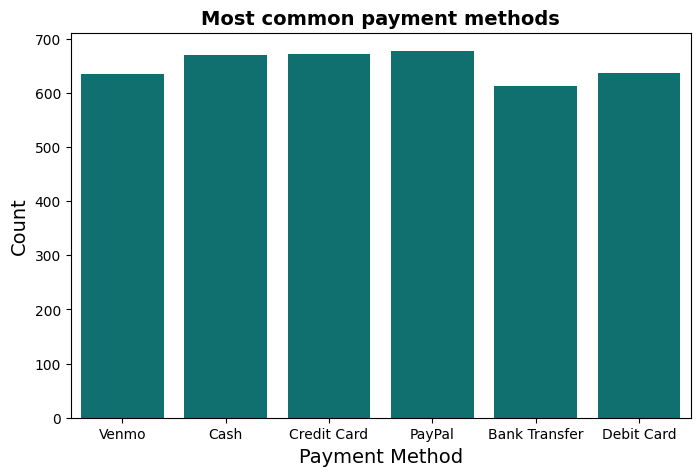

In [17]:
plt.figure(figsize= [8,5])
sns.countplot(data= df, x= 'Payment Method', color= 'teal')
plt.title('Most common payment methods', fontsize= 14, fontweight= 'bold')
plt.xlabel('Payment Method', fontsize= 14)
plt.ylabel('Count', fontsize= 14)
plt.show()

Business Takeaway: The store is doing an excellent job by providing a seamless, multi-channel checkout experience. Since no single method dominates, it is crucial to keep all payment options active and optimized to avoid losing any segment of customers.

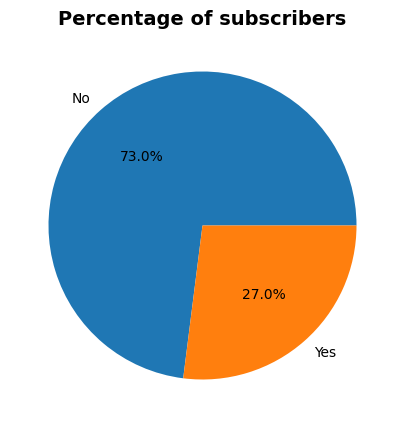

In [18]:
Subscription_Status_percentage = df['Subscription Status'].value_counts(normalize= True)
plt.figure(figsize= [8,5])
plt.pie(Subscription_Status_percentage, labels= Subscription_Status_percentage.index, autopct= '%.1f%%')
plt.title('Percentage of subscribers', fontsize= 14, fontweight= 'bold')
plt.show()



Low Conversion (73% Non-Subscribers): This indicates a huge untapped segment, likely due to either a lack of marketing promotion or unappealing subscription benefits.

Action Plan: The business must improve promotional marketing at checkout and introduce exclusive perks or discounts to motivate regular customers to subscribe.

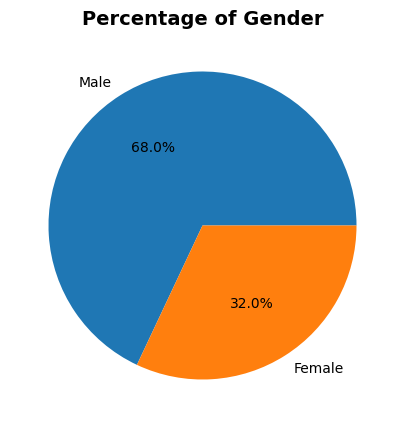

In [19]:
Gender_percentage = df['Gender'].value_counts(normalize= True)
plt.figure(figsize= [8,5])
plt.pie(Gender_percentage, labels= Gender_percentage.index, autopct= '%.1f%%')
plt.title('Percentage of Gender', fontsize= 14, fontweight= 'bold')
plt.show()



Gender Gap (68% Male vs. 32% Female): The data shows a significant gap where male customers heavily dominate store sales.

Action Plan: The business must launch aggressive, high-value promotional offers and exclusive discounts tailored specifically for women to bridge this gap and capture the untapped female market.

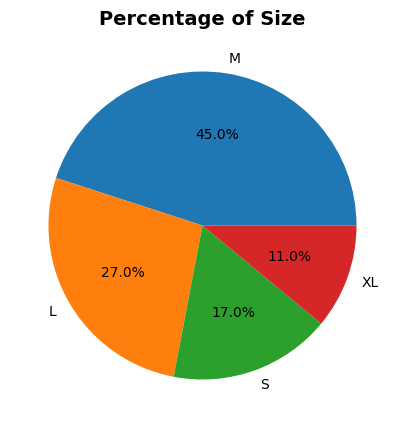

In [20]:
Size_percentage = df['Size'].value_counts(normalize= True)
plt.figure(figsize= [8,5])
plt.pie(Size_percentage, labels= Size_percentage.index, autopct= '%.1f%%')
plt.title('Percentage of Size', fontsize= 14, fontweight= 'bold')
plt.show()



M & L Dominance (72%): Medium and Large are the top-selling sizes, driving nearly three-quarters of total sales.

Action Plan: Maximize stock for sizes M and L to meet high demand, and decrease inventory for size XL to cut costs and prevent unsold stock.

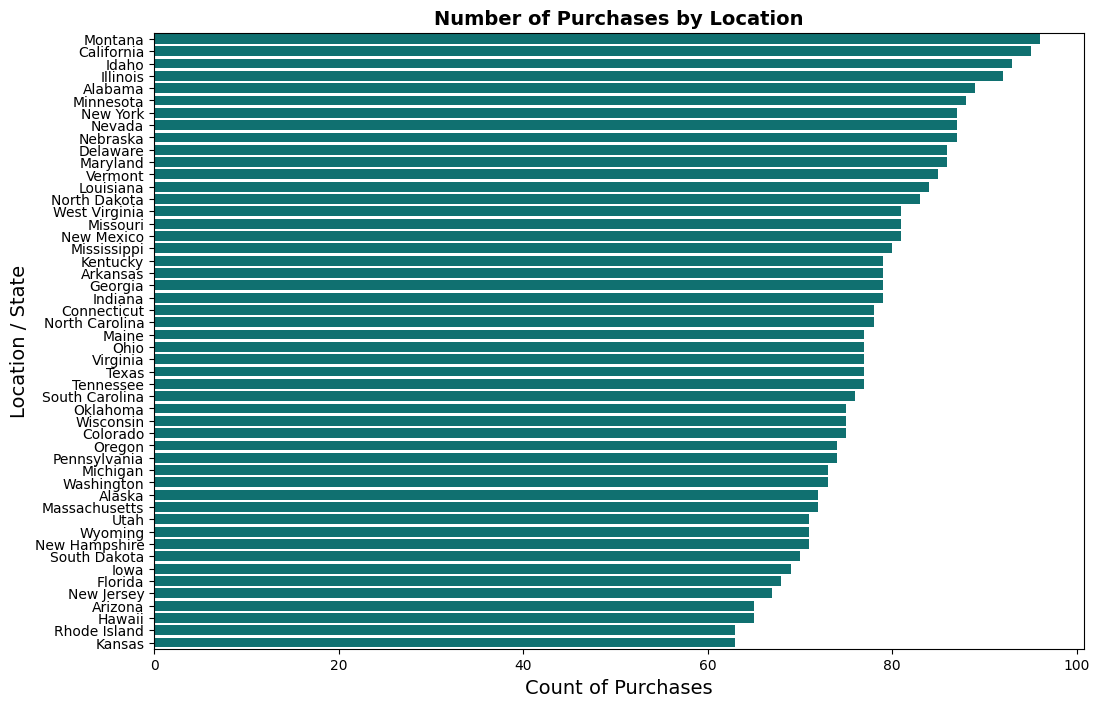

In [21]:
plt.figure(figsize= [12,8])
sns.countplot(data= df, y= 'Location',order=df['Location'].value_counts().index, color= 'teal')
plt.title('Number of Purchases by Location', fontsize= 14, fontweight= 'bold')
plt.xlabel('Count of Purchases', fontsize= 14)
plt.ylabel('Location / State', fontsize= 14)

plt.show()



Top Performing Locations: Montana, California, and Idaho are the highest-grossing states with the maximum number of purchases, making them ideal for expanding physical stores and increasing marketing budgets.

Underperforming Locations: Kansas, Rhode Island, Hawaii, and Arizona show the lowest purchasing activity.

Action Plan: The business should consider closing underperforming physical stores in the lowest-ranked states to save operational costs, transitioning those regions to a pure online-delivery model.

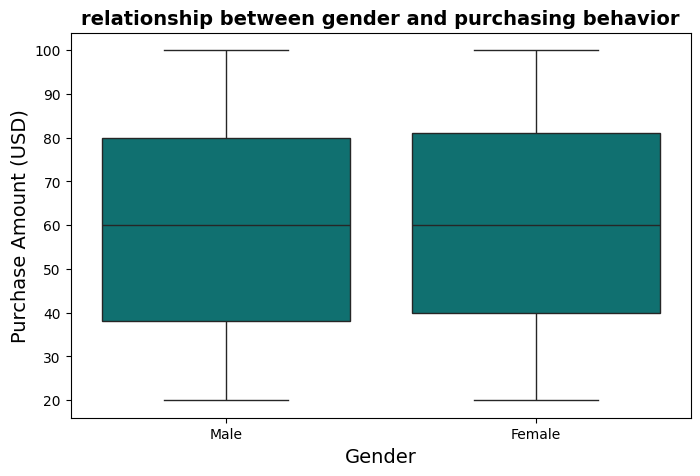

In [22]:
plt.figure(figsize= [8,5])
sns.boxplot(data= df, x= 'Gender', y= 'Purchase Amount (USD)', color= 'teal')
plt.title('relationship between gender and purchasing behavior', fontsize= 14, fontweight= 'bold')
plt.xlabel('Gender', fontsize= 14)
plt.ylabel('Purchase Amount (USD)', fontsize= 14)

plt.show()

No Significant Difference: There is no significant relationship between gender and the purchase amount; both males and females have almost identical spending distributions, with a median purchase value around $60

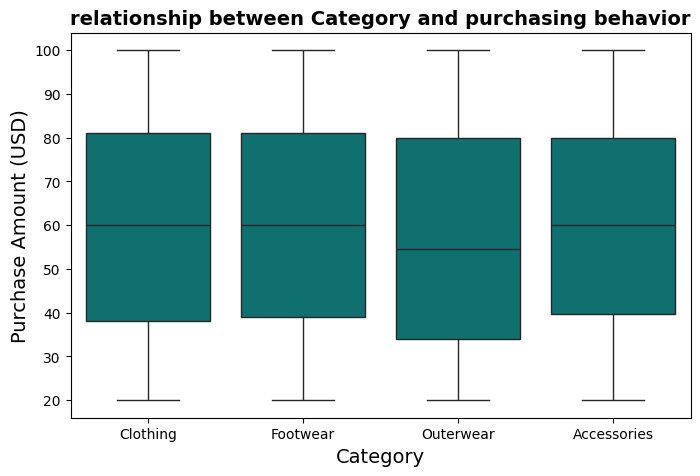

In [23]:
plt.figure(figsize= [8,5])
sns.boxplot(data= df, x= 'Category', y= 'Purchase Amount (USD)', color= 'teal')
plt.title('relationship between Category and purchasing behavior', fontsize= 14, fontweight= 'bold')
plt.xlabel('Category', fontsize= 14)
plt.ylabel('Purchase Amount (USD)', fontsize= 14)

plt.show()

Similar Distributions: Clothing, Footwear, and Accessories share the exact same median purchase amount (60), generating slightly higher individual transaction values compared to Outerwear (55)

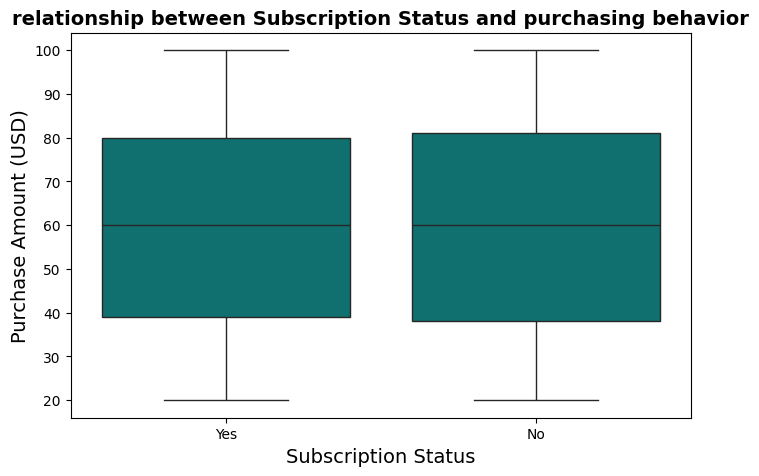

In [24]:
plt.figure(figsize= [8,5])
sns.boxplot(data= df, x= 'Subscription Status', y= 'Purchase Amount (USD)', color= 'teal')
plt.title('relationship between Subscription Status and purchasing behavior', fontsize= 14, fontweight= 'bold')
plt.xlabel('Subscription Status', fontsize= 14)
plt.ylabel('Purchase Amount (USD)', fontsize= 14)

plt.show()

Subscription status has a negligible effect on spending, with both groups sharing a 60 median purchase value, though non-subscribed customers show a fractionally higher upper spending limit (81 vs 80)

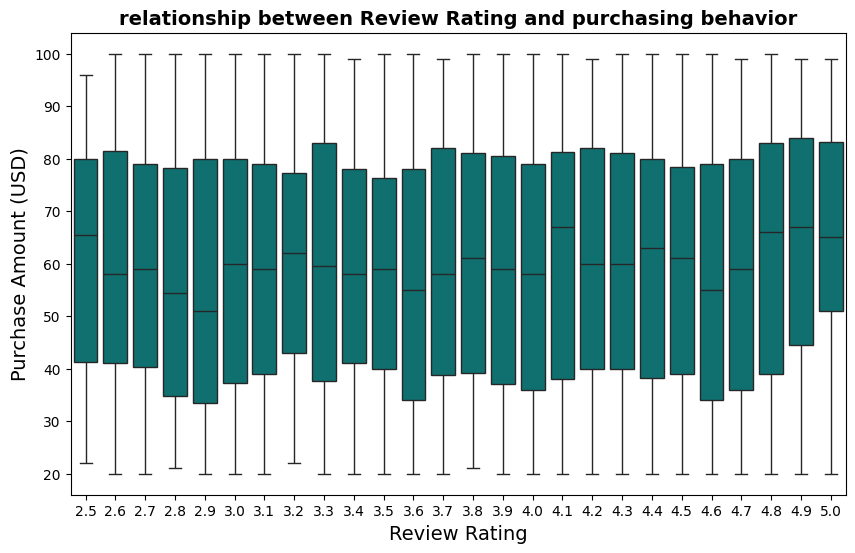

In [25]:
plt.figure(figsize= [10,6])
sns.boxplot(data= df, x= 'Review Rating', y= 'Purchase Amount (USD)', color= 'teal')
plt.title('relationship between Review Rating and purchasing behavior', fontsize= 14, fontweight= 'bold')
plt.xlabel('Review Rating', fontsize= 14)
plt.ylabel('Purchase Amount (USD)', fontsize= 14)

plt.show()

The relationship is weak and non-linear, as evidenced by significant drops at certain ratings like 4.6. However, a slight upward trend is only visible at the extreme top ratings (4.9 - 5.0), where purchase amounts strictly shift higher

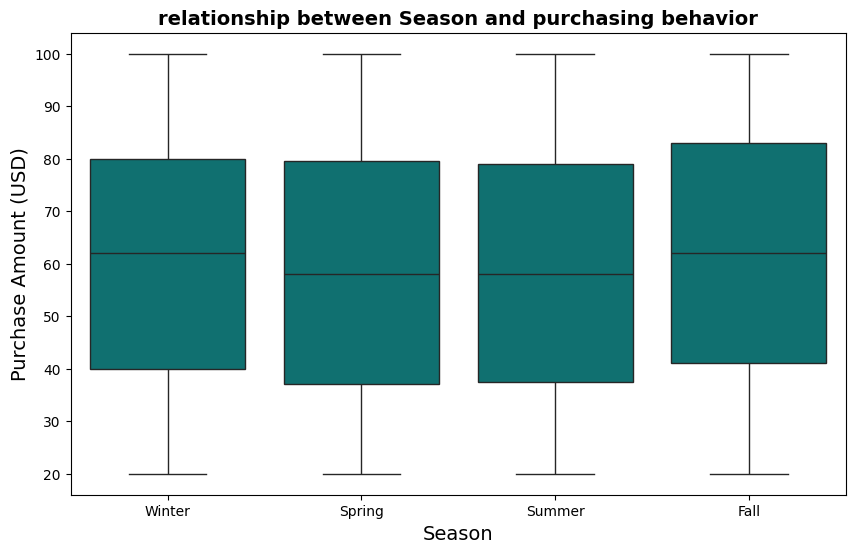

In [26]:
plt.figure(figsize= [10,6])
sns.boxplot(data= df, x= 'Season', y= 'Purchase Amount (USD)', color= 'teal')
plt.title('relationship between Season and purchasing behavior', fontsize= 14, fontweight= 'bold')
plt.xlabel('Season', fontsize= 14)
plt.ylabel('Purchase Amount (USD)', fontsize= 14)

plt.show()

Minor Seasonal Effect: Purchasing behavior shows a slight seasonal variation. Customers spend more per transaction during Fall and Winter (median 62) compared to a noticeable drop during Spring and Summer (median 58)

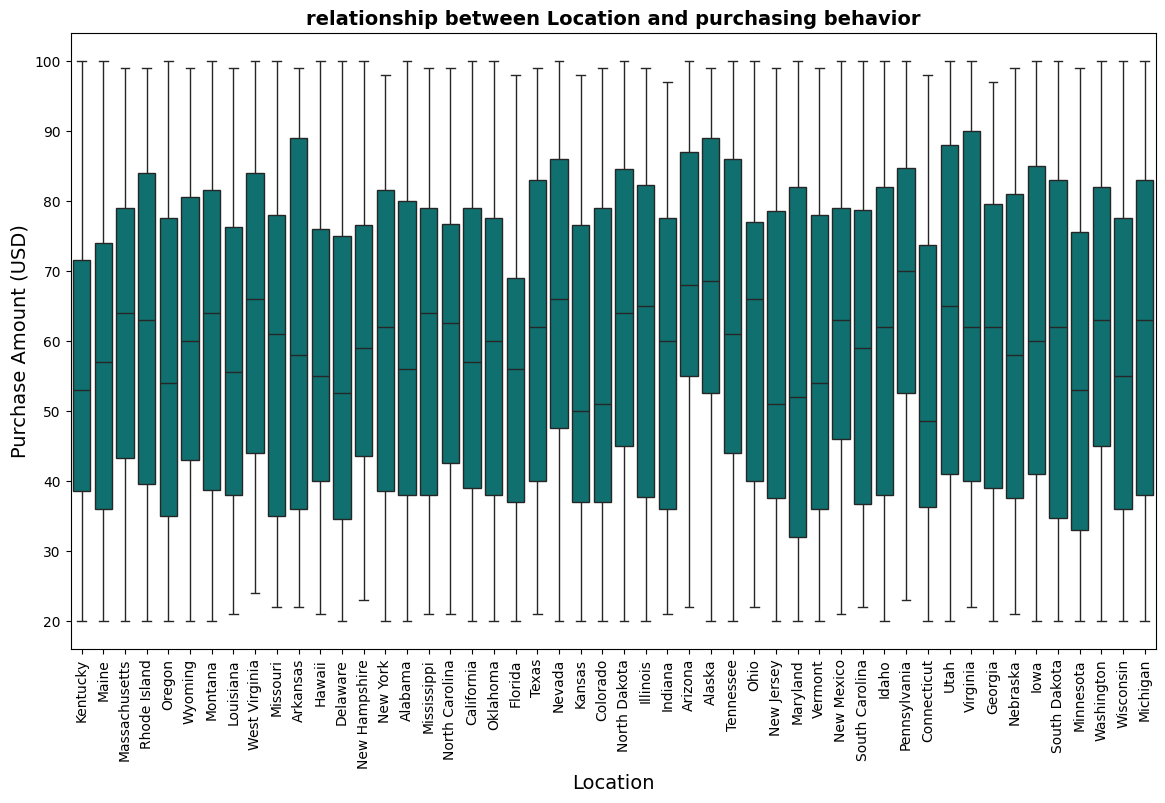

In [27]:
plt.figure(figsize= [14,8])
sns.boxplot(data= df, x= 'Location', y= 'Purchase Amount (USD)', color= 'teal')
plt.title('relationship between Location and purchasing behavior', fontsize= 14, fontweight= 'bold')
plt.xlabel('Location', fontsize= 14)
plt.ylabel('Purchase Amount (USD)', fontsize= 14)
plt.xticks(rotation = 90)

plt.show()

Highest Average Spending Per Transaction: Alaska and Virginia.

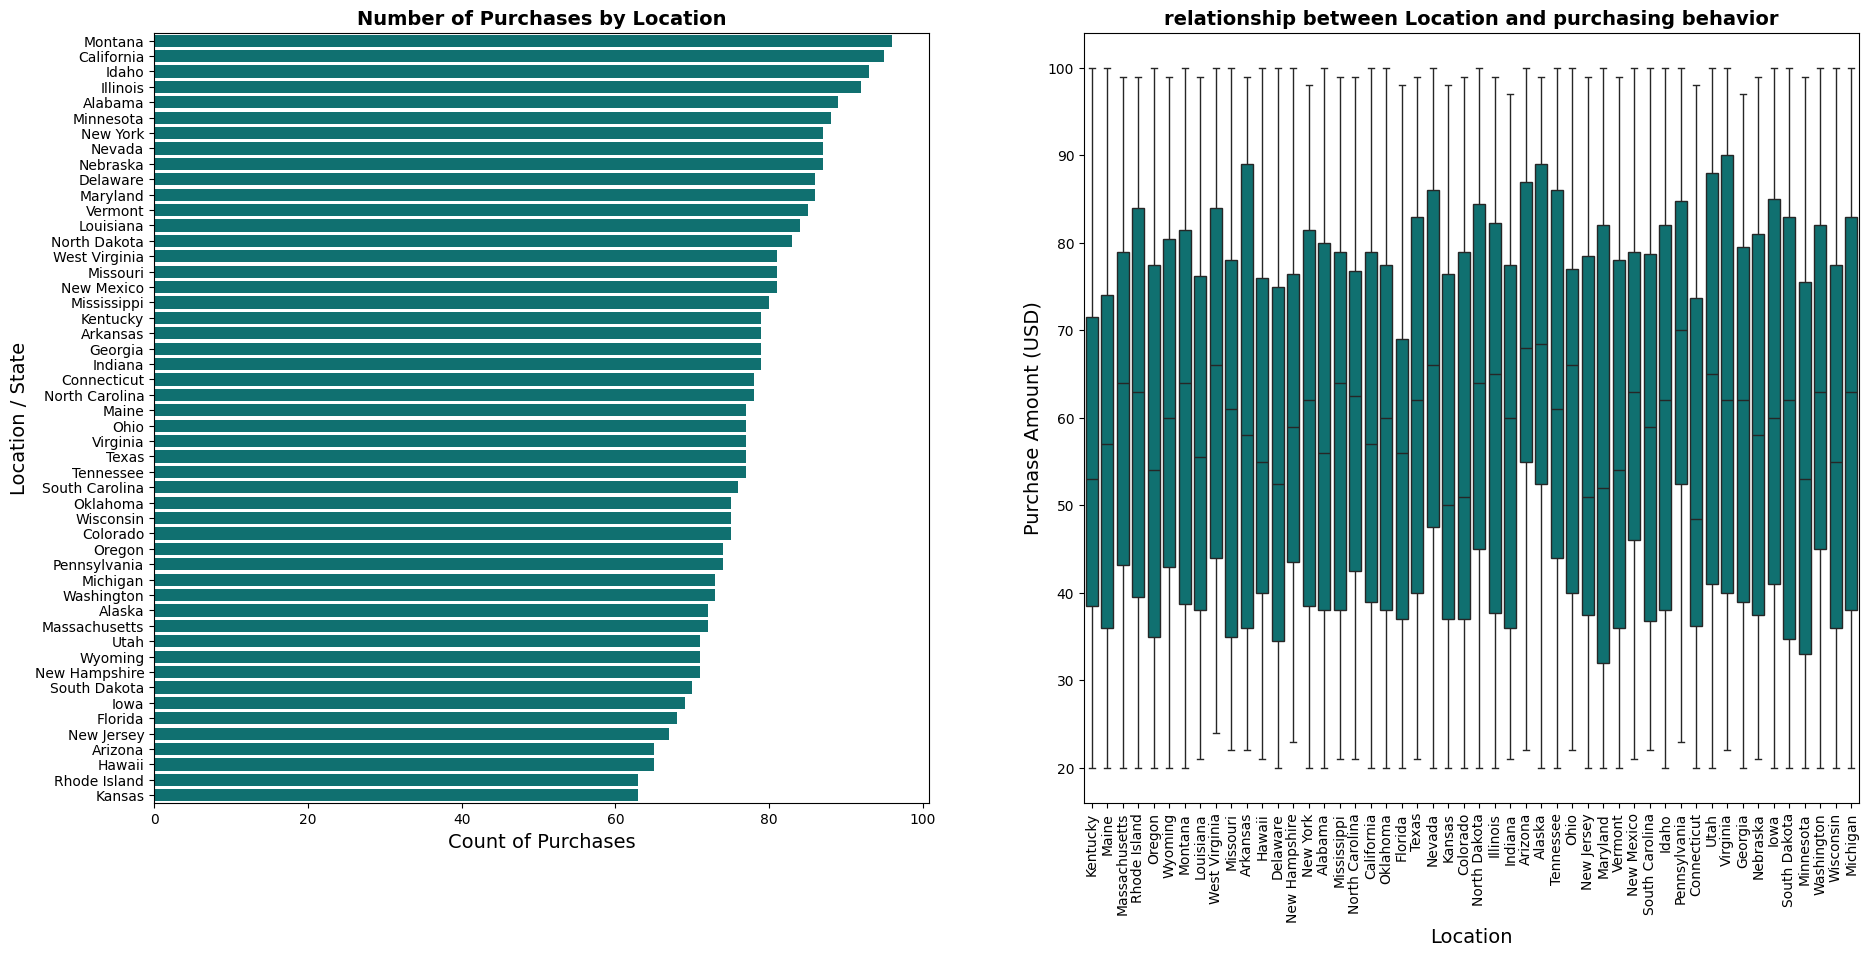

In [28]:
plt.figure(figsize=[22, 10])
plt.subplot(1, 2, 1);
sns.countplot(data= df, y= 'Location',order=df['Location'].value_counts().index, color= 'teal');
plt.title('Number of Purchases by Location', fontsize= 14, fontweight= 'bold');
plt.xlabel('Count of Purchases', fontsize= 14);
plt.ylabel('Location / State', fontsize= 14);



plt.subplot(1, 2, 2);
sns.boxplot(data= df, x= 'Location', y= 'Purchase Amount (USD)', color= 'teal');
plt.title('relationship between Location and purchasing behavior', fontsize= 14, fontweight= 'bold');
plt.xlabel('Location', fontsize= 14);
plt.ylabel('Purchase Amount (USD)', fontsize= 14);
plt.xticks(rotation = 90);


The Volume vs. Value Paradox: States with the highest number of sales (Montana) have a lower average bill per customer. Conversely, states where customers spend the most per transaction (Alaska and Virginia) have the lowest number of buyers.

Action Plan (Promotional Strategy):

For High-Volume States (e.g., Montana): Launch Bundle Offers to encourage customers to buy multiple items together, which will successfully increase their average order value.

For High-Value States (e.g., Alaska & Virginia): Launch Customer Acquisition Campaigns to attract new buyers and expand the customer base in these highly profitable regions.

Text(0.5, 1.0, 'Correlation Matrix of Numerical Features')

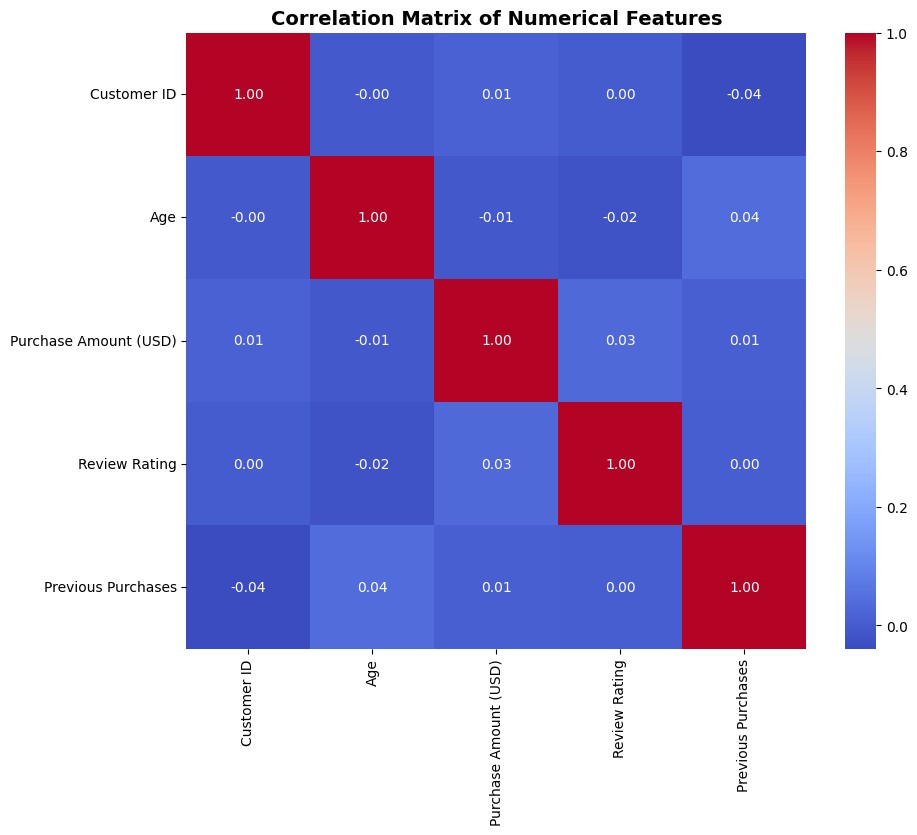

In [29]:
plt.figure(figsize= [10,8])
sns.heatmap(df.corr(numeric_only= True), annot= True, cmap = 'coolwarm', fmt= '.2f')
plt.title('Correlation Matrix of Numerical Features', fontsize=14, fontweight='bold')

There are no strong linear relationships or hidden patterns among these numeric variables, meaning each feature behaves independently within the dataset.

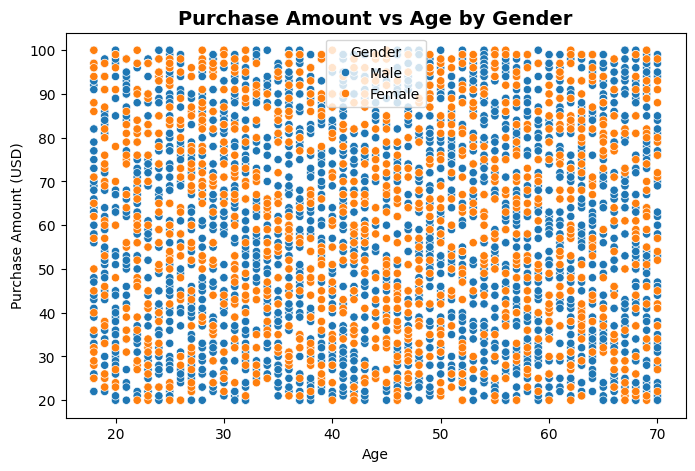

In [31]:
plt.figure(figsize= [8,5])
sns.scatterplot(data= df, x= 'Age', y= 'Purchase Amount (USD)', hue= 'Gender')
plt.title('Purchase Amount vs Age by Gender', fontsize=14, fontweight='bold')
plt.xlabel('Age')
plt.ylabel('Purchase Amount (USD)')


plt.show()

No Distinct Pattern: The scatter plot shows a completely random and uniform distribution of points. This proves that there is no relationship between a customer's age and how much they spend per transaction, and both genders share identical spending distributions.

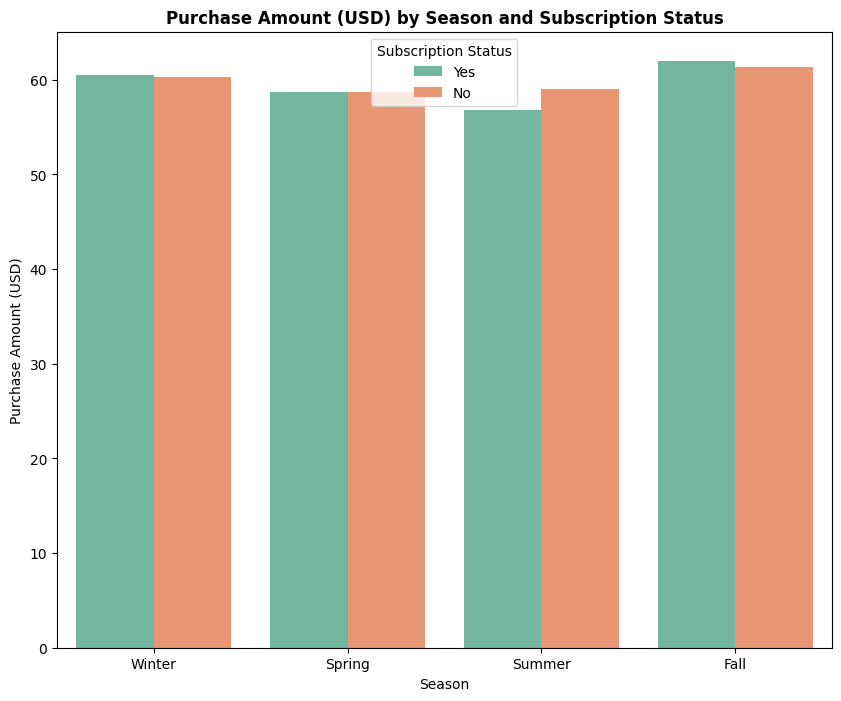

In [37]:
plt.figure(figsize= [10,8])
sns.barplot(data= df, x= 'Season', y= 'Purchase Amount (USD)', hue= 'Subscription Status', palette='Set2', errorbar=None)
plt.title('Purchase Amount (USD) by Season and Subscription Status', fontsize=12, fontweight='bold')
plt.xlabel('Season')
plt.ylabel('Purchase Amount (USD)')
plt.show()

The average purchase amount is nearly identical between subscribers and non-subscribers across all four seasons. Having a subscription status does not influence customers to spend more money per transaction, and spending behavior remains completely stable throughout the year.

Text(0, 0.5, 'Purchase Amount (USD)')

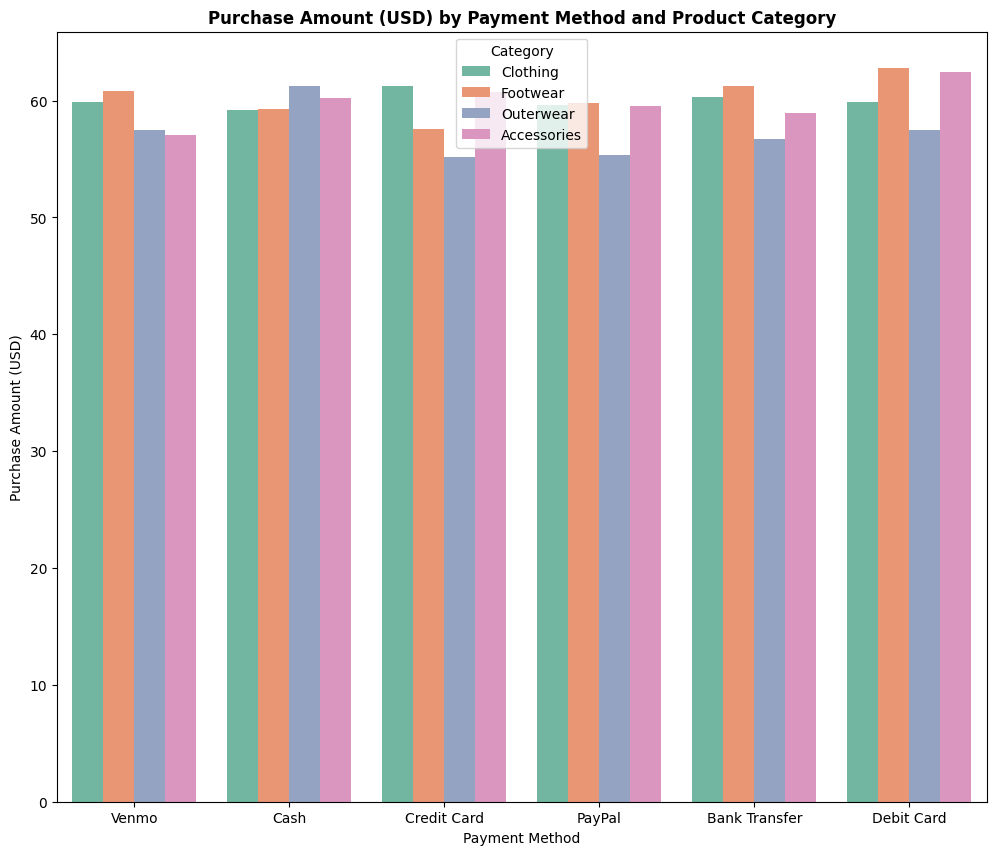

In [46]:
plt.figure(figsize= [12,10])
sns.barplot(data=df, x='Payment Method', y='Purchase Amount (USD)', hue='Category', errorbar=None, palette='Set2')
plt.title('Purchase Amount (USD) by Payment Method and Product Category', fontsize=12, fontweight='bold')
plt.xlabel('Payment Method')
plt.ylabel('Purchase Amount (USD)')

No Impact: A customer's choice of payment method does not influence the product category they buy or how much money they spend.

1. Who are the main customers?

Gender: The majority of the customers are Males, accounting for 68% of the total purchases, while Females account for 32%

2. What are the most successful product categories?
Top Performing Category: Clothing is by far the most successful and popular category, dominating sales with over 1,700 items purchased.

Runner-Up Category: Accessories comes in second place as a highly successful segment, with around 1,250 items sold.

Lowest Performing Category: Outerwear is the least successful category, generating the lowest sales volume (around 300 items)

3. What factors influence customer purchases?
No Strong Influencing Factors: Based on the Correlation Matrix and Multivariate analysis, numerical factors such as Age, Review Ratings, and Previous Purchases have a near-zero correlation with the purchase amount.

Demographics and Seasons: Customer spending per transaction remains completely stable (around $55 to $63) regardless of Gender, Subscription Status, Payment Method, or the Season of the year.

Key Driver: The primary factor driving volume (number of purchases) is the Product Category itself, where customers heavily lean toward buying Clothing and Accessories over Outerwear.

4. What recommendations can improve business decisions?
Target Female Customers: Since females account for only 32% of purchases, the marketing team should launch tailored campaigns, exclusive discounts, or introduce new sub-categories tailored to women to capture this untapped market share.

Revamp the Subscription Model: With the majority of buyers being non-subscribers, the company needs to offer more attractive loyalty rewards, exclusive perks, and first-time sign-up discounts to convert casual shoppers into loyal subscribers.

Optimize Regional Strategy (The State Dilemma): To solve the issue where high-volume states aren't the highest-spending ones, the business should:

In High-Volume States: Push premium products, bundles, or cross-selling strategies to increase the average order value.

In High-Spending States: Run local awareness campaigns and ads to increase the customer base and order volume.

Conclusion:


In conclusion, this analysis reveals that the store has a stable and consistent purchasing pattern across all demographic groups and payment methods, with a powerful reliance on Male buyers and the Clothing category. By focusing on expanding the female customer base, upgrading the subscription benefits, and aligning regional marketing strategies based on volume versus spending, the business can significantly unlock new growth opportunities and maximize overall revenue.